# Change evidence review

**Recipe 25** · Level 3 (Intermediate) · Decision type: `Noul`

Check whether a proposed change includes sufficient implementation, validation, and rollback evidence so a deterministic checklist can identify review gaps.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S04: [TypeSafe AI: How to build with TypeSafe](https://docs.typesafe.ai/concepts/how-to-build-with-system-one)

## What you will build

A review checklist over 40 fabricated change records: change-ticket narratives, each with an Implementation section, a Validation section and a Rollback section, describing a proposed software change. Jev answers three independent `Noul` propositions about the same record in one request: does it supply sufficient implementation evidence, sufficient validation evidence, and sufficient rollback evidence. The fixtures cover all eight combinations the three propositions can take together, so every pair of them is exercised in all four of its own combinations -- each alone, both at once, and neither -- without a fixture group dedicated to any one pair. Three further records, one per proposition, mention that evidence type without actually supplying it: the hard case this use case names directly, a record that mentions a rollback plan without describing one. Python composes the three answers into one of three outcomes -- `ready`, `gaps` or `review` -- in a single tested function, using a business threshold chosen per proposition and one confidence gate shared by all three. The evaluation reports precision and recall for each proposition on its own, and, at the level of the whole change record, how often the composed gap list matches the record's gold combination of evidence types exactly -- real-fixture evidence that each proposition can change the composed outcome on its own.

## Setup and run mode

The notebook runs from its own folder with the standard library and `jev_cookbook` only. `get_backend(fixtures=...)` replays the 40 stored answers in `fixtures/responses.json` offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls to the same three question definitions and changes nothing else. `run_header` states which mode ran. Two labels may follow a number below. `(a pipeline check, not a Jev result)` marks a synthetic or scripted run; a recorded or live run does not print it, and its header says which mode ran. `(a selection step, not a reported result)` marks a number from `validation`, the split settings are chosen on; it is never a result to report. A line with neither label, such as an individual answer or a per-example line, still comes from the mode the header names. Each change record needs exactly one request (all three propositions are independent questions over the same record, so they are asked together), so this notebook's request count and its decision count are not the same thing: 40 requests produce 120 label decisions, three per record.

In [1]:
from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    confusion_matrix,
    evaluate_outcomes,
    evaluate_selective,
    evaluate_threshold,
    exact_set_match,
    pool_label_decisions,
    pool_label_outcomes,
    select_confidence_threshold,
    select_threshold,
    selective_curve,
    threshold_sweep,
)
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path
from jev_cookbook.simulation import ReviewQueue
from jev_cookbook.style import (
    apply_style,
    plot_answer_probabilities,
    plot_confusion_matrix,
    plot_risk_coverage,
    plot_threshold_sweep,
    run_header,
    show_answer,
)

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path())
questions = helpers.build_questions()
# N for the header is the number of examples the metrics are about: validation and test. The
# two demo records are shown below but never scored.
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
# CONTRIBUTING.md section 2: a number from the validation split is a selection step, not a
# result. A synthetic or scripted run carries both labels on a validation number.
selection = " (a selection step, not a reported result)"

# Every record needs at most one request; this cache makes sure a record shown individually
# and later scored in its split is decided once, so the whole notebook makes exactly one
# request per fixture record in live mode, never more.
decided = {}


def decide(example):
    if example.id not in decided:
        decided[example.id] = backend.decide(helpers.build_state(example.fields), questions)
    return decided[example.id]


run_header(25, "Change evidence review", backend=backend, n_examples=len(scored))

Recipe 25: Change evidence review
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 38 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The state is everything Jev sees, and Python builds it. Each example in `fixtures/inputs.jsonl` carries `fields`: a `record`, the full fabricated change-ticket narrative. `build_state` passes the record on unchanged -- unlike a retrieved document a reviewer skims, a change record submitted for review is read in full by whoever approves it, so there is nothing for Python to trim before Jev sees the same thing a human reviewer would. The example id never passes through the model either; it stays in Python and is attached to the outcome at the end.

In [2]:
import json

demo = {e.id: e for e in examples if e.split == "demo"}
ready_demo = demo["d01"]
print("Python has:")
print(json.dumps(ready_demo.fields, indent=2))
state = helpers.build_state(ready_demo.fields)
print("Jev sees:")
print(json.dumps(state, indent=2))

Python has:
{
  "record": "Add dynamic discount rule to checkout\n\nImplementation: Added a `loyalty_discount` rule to `checkout/pricing.py` that applies a 10% discount for accounts active over two years, deployed to checkout-api pods 1-6.\n\nValidation: Ran the pricing regression suite (88 cases) in staging; all passed, and manually verified the discount applied correctly for 10 sample accounts of varying age.\n\nRollback: Revert commit 4a7e21c and redeploy checkout-api at the previous tag (checkout-api:6.3.0); the change touches no stored data, so no further reversal is needed."
}
Jev sees:
{
  "record": "Add dynamic discount rule to checkout\n\nImplementation: Added a `loyalty_discount` rule to `checkout/pricing.py` that applies a 10% discount for accounts active over two years, deployed to checkout-api pods 1-6.\n\nValidation: Ran the pricing regression suite (88 cases) in staging; all passed, and manually verified the discount applied correctly for 10 sample accounts of varying ag

## The questions

Three independent propositions describe the same change record, so `backend.decide` sends them together in one request: TypeSafe's primitives page ([S02](https://docs.typesafe.ai/primitives)) says independent questions over the same state belong in one request. Each is written as a statement that is true or false, as CONTRIBUTING.md requires of a `Noul`, not as a question: `implementation_evidence` is true when the record names a specific component, file, or step changed; `validation_evidence` is true when it names a specific test or check and its result; `rollback_evidence` is true when it names the concrete steps that would undo the change. They stay three separate `Noul` propositions rather than one `Choice` because a change record can independently provide or lack each kind of evidence -- a `Choice` would force Jev to adjudicate the combination itself, when the combination is exactly what Python decomposes and composes below. Each name ends `_evidence` so that, in prose below, a proposition is never confused with the `validation` or `test` fixture split of the same word.

In [3]:
for name, question in questions.items():
    print(name)
    print(" ", question.instructions)
    for side, description in question.criteria.items():
        print(f"    {side}: {description}")

implementation_evidence
  The change record describes what was actually implemented in enough concrete detail to identify the change that was made.
    true: The record names specific components, files, configuration, or steps that were changed, with enough detail that a reader could identify exactly what was modified.
    false: The record does not say what was actually changed, or only vaguely gestures at it (for example 'the change was made' or 'implementation attached') without naming any specific component, file, or step.
validation_evidence
  The change record describes how the change was tested or validated before being proposed for deployment, including what was checked and what the result was.
    true: The record names a specific test, check, or validation activity that was performed against this change, and states its outcome -- for example which suite ran, what was checked, and that it passed or what it showed.
    false: The record does not describe any specific validation

## One answer up close

Before any aggregate, look at four typed records: a change with all three evidence types sufficient, a change that mentions a rollback plan without describing one (the hard case this use case names), a change missing all three evidence types at once, and a change whose record reads as a near-miss on one evidence type -- plausible enough that Python is not confident enough to trust either reading. Each answer holds just `noul`, the probability that its proposition is true, and a `provenance` line; a Noul has no separate confidence field in the API response at all (S02, S03), unlike `Choice` and `Score`. All four come from `demo` or `validation`, never from `test`, which is reported once further down.

Add dynamic discount rule to checkout

Implementation: Added a `loyalty_discount` rule to `checkout/pricing.py` that applies a 10% discount for accounts active over two years, deployed to checkout-api pods 1-6.

Validation: Ran the pricing regression suite (88 cases) in staging; all passed, and manually verified the discount applied correctly for 10 sample accounts of varying age.

Rollback: Revert commit 4a7e21c and redeploy checkout-api at the previous tag (checkout-api:6.3.0); the change touches no stored data, so no further reversal is needed.
Noul: 0.95 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.96 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.94 probability of yes (0 is no, 1 is yes)
Provenance: synthetic


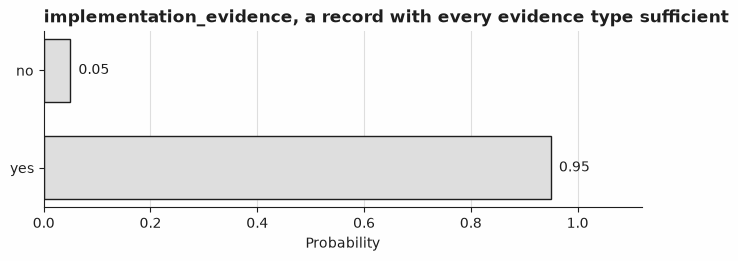

In [4]:
ready_answer = decide(ready_demo)
print(ready_demo.fields["record"])
show_answer(ready_answer["implementation_evidence"])
show_answer(ready_answer["validation_evidence"])
show_answer(ready_answer["rollback_evidence"])
plot_answer_probabilities(
    ready_answer["implementation_evidence"],
    title="implementation_evidence, a record with every evidence type sufficient",
)

Every stored probability reads high: implementation 0.95, validation 0.96, rollback 0.94. This is the clean case the checklist below reports `ready` for: nothing missing, nothing to review.

In [5]:
gap_demo = demo["d02"]
gap_answer = decide(gap_demo)
print(gap_demo.fields["record"])
show_answer(gap_answer["implementation_evidence"])
show_answer(gap_answer["validation_evidence"])
show_answer(gap_answer["rollback_evidence"])

Add regional failover for checkout

Implementation: Added a secondary-region failover path to `checkout/router.py`, switching traffic to the eu-west pool when the primary region's health check fails twice in a row.

Validation: Forced a primary-region health-check failure in staging and confirmed traffic switched to eu-west within 8 seconds with no dropped checkouts.

Rollback: A rollback plan is in place.
Noul: 0.93 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.92 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.09 probability of yes (0 is no, 1 is yes)
Provenance: synthetic


Implementation and validation read high (0.93, 0.92): the record names the specific failover path it added and the specific test it ran. Rollback reads low (0.09): "a rollback plan is in place" names no commit, backup, or configuration to restore, so there is nothing a reader could actually act on if the change needed to be undone. This is the use case's own named hard case -- a record that mentions a rollback plan without describing one -- and the [gold label](../../docs/glossary.md#gold-label) for `rollback_evidence` on this record is `False`.

In [6]:
multi_gap_example = next(e for e in examples if e.id == "v15")
multi_gap_answer = decide(multi_gap_example)
print(multi_gap_example.fields["record"])
show_answer(multi_gap_answer["implementation_evidence"])
show_answer(multi_gap_answer["validation_evidence"])
show_answer(multi_gap_answer["rollback_evidence"])

Externalize shipping rate table

Implementation: The change has been made as discussed.

Validation: Testing was completed successfully.

Rollback: We can roll this back if needed.
Noul: 0.05 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.05 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.05 probability of yes (0 is no, 1 is yes)
Provenance: synthetic


All three readings are low (0.05 each): the record states only that a fix was "made as discussed," testing "passed," and that rollback is "standard process" -- none of the three sections names anything a reader could check or act on. The checklist below reports every one of the three evidence types as a gap on this record, not only the worst of them.

In [7]:
review_example = next(e for e in examples if e.id == "v19")
review_answer = decide(review_example)
print(review_example.fields["record"])
show_answer(review_answer["implementation_evidence"])
show_answer(review_answer["validation_evidence"])
show_answer(review_answer["rollback_evidence"])

Increase payments-gateway retries

Implementation: Reconfigured the `payments-gateway` retry policy in `gateway.yaml` from 3 attempts to 5, with exponential backoff starting at 200ms.

Validation: Simulated gateway timeouts in staging and confirmed the retry policy made exactly 5 attempts with the expected backoff intervals, logged in the test run.

Rollback: Rollback plan documented in RUNBOOK-204, owned by the payments on-call rotation and reviewed before this deploy.
Noul: 0.96 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.97 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.89 probability of yes (0 is no, 1 is yes)
Provenance: synthetic


Implementation and validation read confidently high. Rollback reads 0.89 -- above where "Python's part" below ends up freezing the business threshold for sufficiency, so the raw reading alone would call this record's rollback evidence sufficient -- but its stored [confidence](../../docs/glossary.md#confidence), `|2(0.89) - 1| = 0.78`, is low enough that the [confidence gate](../../docs/glossary.md#confidence-gate) below sends the whole record to [review](../../docs/glossary.md#review) rather than act on a reading this close to the line. The gold label for `rollback_evidence` here is `False`: the record names the plan but, like the demo record above, does not describe it.

## Python's part

Jev supplies three probabilities; everything that happens with them is code. `helpers.decide_labels` turns each one into a [business threshold](../../docs/glossary.md#business-threshold) tag -- `implementation_evidence >= t_implementation`, and likewise for the other two -- and checks it against one shared [confidence gate](../../docs/glossary.md#confidence-gate), `noul_confidence(noul) >= gate`, for any of the three. `helpers.review_checklist` then composes the three label decisions into one outcome: a record with any label gated goes to an explicit [review](../../docs/glossary.md#review) outcome, whichever way its tags read; otherwise the gap list is every proposition whose tag reads insufficient, and an empty gap list reports `ready` while a non-empty one reports `gaps` naming exactly which evidence types are missing. `tests/test_helpers.py` checks every branch directly, every one of the eight possible gap combinations, and -- on real, committed `test` records -- that flipping any one stored decision on its own, holding the other two fixed, changes the composed outcome.

Each per-proposition threshold is chosen independently, by F1, and the one shared gate is chosen afterwards from all three propositions' pooled decisions -- all four on `validation`, then frozen.

In [8]:
val_examples = [e for e in examples if e.split == "validation"]
val_answers = {e.id: decide(e) for e in val_examples}
val_noul = {
    label: [val_answers[e.id][label].noul for e in val_examples] for label in helpers.LABELS
}
val_gold = {label: [labels[e.id][label] for e in val_examples] for label in helpers.LABELS}

thresholds = {
    label: select_threshold(val_gold[label], val_noul[label], objective="f1")
    for label in helpers.LABELS
}
for label in helpers.LABELS:
    print(
        f"{label} business threshold, frozen from here on: {thresholds[label]:.3f}{selection}{check}"
    )

val_ids = [e.id for e in val_examples]
val_pooled_correct, val_pooled_confidence, val_pooled_keys = pool_label_decisions(
    val_ids, list(helpers.LABELS), val_gold, val_noul, thresholds
)
gate = select_confidence_threshold(val_pooled_correct, val_pooled_confidence, target_accuracy=1.0)
print(f"confidence gate, frozen from here on: {gate:.3f}{selection}{check}")

for shown_id, shown in (
    ("d01", ready_demo),
    ("d02", gap_demo),
    ("v15", multi_gap_example),
    ("v19", review_example),
):
    answer = decide(shown)
    decisions = helpers.decide_labels(answer, thresholds, gate)
    result = helpers.review_checklist(decisions)
    noul_text = ", ".join(f"{label} {answer[label].noul:.2f}" for label in helpers.LABELS)
    print(f"{shown_id}: {noul_text} -> {result.outcome} ({result.reason})")

implementation_evidence business threshold, frozen from here on: 0.830 (a selection step, not a reported result) (a pipeline check, not a Jev result)
validation_evidence business threshold, frozen from here on: 0.850 (a selection step, not a reported result) (a pipeline check, not a Jev result)
rollback_evidence business threshold, frozen from here on: 0.840 (a selection step, not a reported result) (a pipeline check, not a Jev result)
confidence gate, frozen from here on: 0.800 (a selection step, not a reported result) (a pipeline check, not a Jev result)
d01: implementation_evidence 0.95, validation_evidence 0.96, rollback_evidence 0.94 -> ready (all three evidence types are sufficient)
d02: implementation_evidence 0.93, validation_evidence 0.92, rollback_evidence 0.09 -> gaps (missing evidence: rollback_evidence)
v15: implementation_evidence 0.05, validation_evidence 0.05, rollback_evidence 0.05 -> gaps (missing evidence: implementation_evidence, rollback_evidence, validation_eviden

### Why one shared gate, and its blind spot

A multi-label `Noul` rule's three-path pattern -- answer true, answer false, or send a record to a person -- needs every (record, proposition) decision's correctness and confidence pooled before a [coverage](../../docs/glossary.md#coverage) and [risk](../../docs/glossary.md#risk) curve can be drawn over all three propositions at once; `pool_label_decisions` does that pooling, and `selective_curve` is the sanity check that confidence actually separates right answers from wrong ones on this data, shown next rather than asserted, as a single shared gate over three different propositions. `|2p - 1|` measures distance from an even split, not distance from whichever business threshold a proposition happens to use: a proposition whose own threshold sits near 1.0 can read as confidently right even a little below it, because `noul_confidence` is never told where that threshold is. The gate chosen here is structurally blind to exactly that shape of error, on any of the three, and "Evaluation" below shows one.

pooled, 57 label decisions (a selection step, not a reported result) (a pipeline check, not a Jev result)
ungated accuracy: 0.9474 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate >= 0.980: coverage 0.0526, accuracy 1.0000, risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate >= 0.960: coverage 0.1754, accuracy 1.0000, risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate >= 0.940: coverage 0.3509, accuracy 1.0000, risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate >= 0.920: coverage 0.4912, accuracy 1.0000, risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate >= 0.900: coverage 0.6316, accuracy 1.0000, risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate >= 0.880: coverage 0.7193, accuracy 1.0000, risk 0.0000 (a selection step

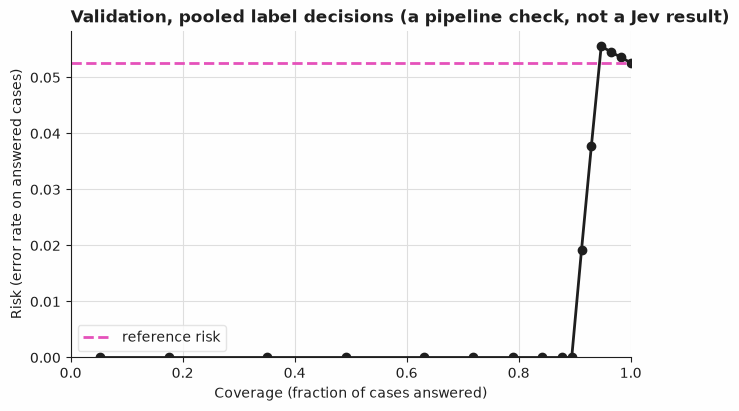

In [9]:
val_curve = selective_curve(val_pooled_correct, val_pooled_confidence)
print(f"pooled, {len(val_pooled_correct)} label decisions{selection}{check}")
print(
    f"ungated accuracy: {sum(val_pooled_correct) / len(val_pooled_correct):.4f}{selection}{check}"
)
for t, cov, acc, risk in zip(
    val_curve.thresholds, val_curve.coverage, val_curve.accuracy, val_curve.risk, strict=True
):
    marker = " <- frozen" if abs(t - gate) < 1e-9 else ""
    print(
        f"  gate >= {t:.3f}: coverage {cov:.4f}, accuracy {acc:.4f}, "
        f"risk {risk:.4f}{marker}{selection}{check}"
    )
plot_risk_coverage(
    val_curve,
    reference_risk=1 - sum(val_pooled_correct) / len(val_pooled_correct),
    title=f"Validation, pooled label decisions{check}",
)

`jev_cookbook.simulation.ReviewQueue` is the shared primitive for the `review` outcome ([docs/simulation.md](../../docs/simulation.md)): `submit` records an item, the reason it was sent, and the typed answer behind that reason, and nothing in it executes anything. `ReviewQueue` itself keeps submission order, oldest first; it does not reorder anything on its own, so a queue that reads sorted is sorted once, before every item is submitted, by `helpers.review_sort_key` -- the lowest of the three propositions' own confidence, so the record Python is least sure about surfaces first. A preview on the four records shown above, with the full item a reviewer would actually see:

In [10]:
preview_items = []
for shown_id, shown in (
    ("d01", ready_demo),
    ("d02", gap_demo),
    ("v15", multi_gap_example),
    ("v19", review_example),
):
    answer = decide(shown)
    decisions = helpers.decide_labels(answer, thresholds, gate)
    result = helpers.review_checklist(decisions)
    if result.outcome == helpers.REVIEW:
        preview_items.append((shown_id, shown, result))

preview_items.sort(key=lambda row: (helpers.review_sort_key(row[2]), row[0]))
print(f"preview: {len(preview_items)} of these four would be queued{selection}{check}")
for shown_id, shown, result in preview_items:
    item = helpers.queue_item(shown_id, shown.fields, result)
    print(f"  {item['id']}: {result.reason}, sort key {helpers.review_sort_key(result):.3f}")
    for label in helpers.LABELS:
        print(
            f"    {label}: noul {item[label]['noul']:.2f}, confidence {item[label]['confidence']:.4f}"
        )

preview: 1 of these four would be queued (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v19: confidence below the threshold, sort key 0.780
    implementation_evidence: noul 0.96, confidence 0.9200
    validation_evidence: noul 0.97, confidence 0.9400
    rollback_evidence: noul 0.89, confidence 0.7800


## Evaluation

Both the three business thresholds and the shared confidence gate were chosen and frozen above, on `validation`. This section reports, per proposition, its own [precision](../../docs/glossary.md#precision) and [recall](../../docs/glossary.md#recall) against its threshold alone (no gate); at task level, the counts `helpers.review_checklist` actually returns and [`evaluate_outcomes`](../../docs/evaluation.md)'s [coverage](../../docs/glossary.md#coverage), [accuracy](../../docs/glossary.md#accuracy) and [risk](../../docs/glossary.md#risk) over the composed outcome; a confusion matrix of the composed outcome against gold; and the use case's own measure -- how often the composed gap list matches the record's gold combination of evidence types exactly. `test` is used once, after every choice above is frozen.

In [11]:
val_results = {
    e.id: helpers.review_checklist(helpers.decide_labels(decide(e), thresholds, gate))
    for e in val_examples
}
val_counts = {helpers.READY: 0, helpers.GAPS: 0, helpers.REVIEW: 0}
for e in val_examples:
    val_counts[val_results[e.id].outcome] += 1
val_accepted = [val_results[e.id].outcome != helpers.REVIEW for e in val_examples]
val_correct = [val_results[e.id].outcome == labels[e.id]["outcome"] for e in val_examples]
val_outcomes = evaluate_outcomes(val_accepted, val_correct)

print(f"validation, {len(val_examples)} records{selection}{check}")
print(
    f"ready: {val_counts[helpers.READY]}  gaps: {val_counts[helpers.GAPS]}  "
    f"review: {val_counts[helpers.REVIEW]}{selection}{check}"
)
print(f"coverage: {val_outcomes.coverage:.4f}{selection}{check}")
print(f"accuracy among answered: {val_outcomes.accuracy:.4f}{selection}{check}")
print(f"risk among answered: {val_outcomes.risk:.4f}{selection}{check}")

validation, 19 records (a selection step, not a reported result) (a pipeline check, not a Jev result)
ready: 2  gaps: 11  review: 6 (a selection step, not a reported result) (a pipeline check, not a Jev result)
coverage: 0.6842 (a selection step, not a reported result) (a pipeline check, not a Jev result)
accuracy among answered: 1.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
risk among answered: 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)


[Precision](../../docs/glossary.md#precision) is the fraction of records tagged sufficient for a proposition that actually are; [recall](../../docs/glossary.md#recall) is the fraction of records genuinely sufficient on that proposition the rule tags at all; [F1](../../docs/glossary.md#f1) is their harmonic mean. The sweep below is `rollback_evidence`'s own business rule alone -- the proposition this use case's named hard case bears on -- over every threshold `select_threshold` considered on `validation`, printed and then drawn.

  threshold 0.020: precision 0.5263, recall 1.0000, f1 0.6897 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  threshold 0.030: precision 0.5882, recall 1.0000, f1 0.7407 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  threshold 0.040: precision 0.6667, recall 1.0000, f1 0.8000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  threshold 0.050: precision 0.7143, recall 1.0000, f1 0.8333 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  threshold 0.070: precision 0.8333, recall 1.0000, f1 0.9091 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  threshold 0.840: precision 0.9091, recall 1.0000, f1 0.9524 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  threshold 0.890: precision 0.9000, recall 0.9000, f1 0.9000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  threshold 0

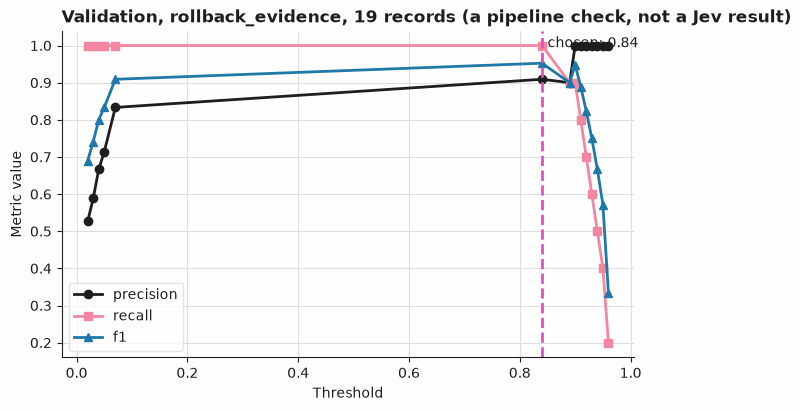

In [12]:
rollback_sweep = threshold_sweep(
    val_gold[helpers.ROLLBACK_EVIDENCE], val_noul[helpers.ROLLBACK_EVIDENCE]
)
for point in rollback_sweep:
    print(
        f"  threshold {point.threshold:.3f}: precision {point.precision:.4f}, "
        f"recall {point.recall:.4f}, f1 {point.f1:.4f}{selection}{check}"
    )
plot_threshold_sweep(
    rollback_sweep,
    chosen=thresholds[helpers.ROLLBACK_EVIDENCE],
    title=f"Validation, rollback_evidence, {len(val_examples)} records{check}",
)

On `test`, each proposition's own business rule, with no gate at all, is reported first with `evaluate_threshold`; then the composed, task-level outcome `helpers.review_checklist` actually returns, and its coverage, accuracy and risk from `evaluate_outcomes`, exactly as for `validation` above.

In [13]:
test_examples = [e for e in examples if e.split == "test"]
test_answers = {e.id: decide(e) for e in test_examples}
test_noul = {
    label: [test_answers[e.id][label].noul for e in test_examples] for label in helpers.LABELS
}
test_gold = {label: [labels[e.id][label] for e in test_examples] for label in helpers.LABELS}

print(f"test, {len(test_examples)} records, every threshold and the gate frozen{check}")
for label in helpers.LABELS:
    point = evaluate_threshold(test_gold[label], test_noul[label], thresholds[label])
    print(
        f"{label} alone: precision {point.precision:.4f}  recall {point.recall:.4f}  "
        f"f1 {point.f1:.4f}{check}"
    )

test_results = {
    e.id: helpers.review_checklist(helpers.decide_labels(decide(e), thresholds, gate))
    for e in test_examples
}
test_counts = {helpers.READY: 0, helpers.GAPS: 0, helpers.REVIEW: 0}
for e in test_examples:
    test_counts[test_results[e.id].outcome] += 1
test_accepted = [test_results[e.id].outcome != helpers.REVIEW for e in test_examples]
test_correct = [test_results[e.id].outcome == labels[e.id]["outcome"] for e in test_examples]
test_outcomes = evaluate_outcomes(test_accepted, test_correct)

print(
    f"ready: {test_counts[helpers.READY]}  gaps: {test_counts[helpers.GAPS]}  "
    f"review: {test_counts[helpers.REVIEW]}{check}"
)
print(f"coverage: {test_outcomes.coverage:.4f}{check}")
print(f"accuracy among answered: {test_outcomes.accuracy:.4f}{check}")
print(f"risk among answered: {test_outcomes.risk:.4f}{check}")

test, 19 records, every threshold and the gate frozen (a pipeline check, not a Jev result)
implementation_evidence alone: precision 0.9000  recall 0.9000  f1 0.9000 (a pipeline check, not a Jev result)
validation_evidence alone: precision 1.0000  recall 0.9000  f1 0.9474 (a pipeline check, not a Jev result)
rollback_evidence alone: precision 0.9000  recall 0.9000  f1 0.9000 (a pipeline check, not a Jev result)
ready: 3  gaps: 10  review: 6 (a pipeline check, not a Jev result)
coverage: 0.6842 (a pipeline check, not a Jev result)
accuracy among answered: 0.9231 (a pipeline check, not a Jev result)
risk among answered: 0.0769 (a pipeline check, not a Jev result)


`validation_evidence`'s own business rule reads precision 1.0000, recall 0.9000 and F1 0.9474 on `test` -- not a perfect score, only zero false positives. `implementation_evidence` and `rollback_evidence` each read lower (F1 0.9000) because each misses two records, not one: a false negative and a false positive apiece -- `t08` and `t17` for implementation, `t14` and `t19` for rollback. This is not guaranteed by the fixture design: the three propositions are independent (every one of the eight combinations appears in this set, so any one of them is free to read true or false on its own regardless of the other two), and `tests/test_helpers.py` proves each proposition can change the composed outcome by flipping a real stored decision. `validation_evidence`'s one miss is `t12`, a false negative: its stored reading, 0.82, falls just under its own 0.85 threshold even though its gold label is `True`. The other eighteen stored `validation_evidence` answers on `test` all land on the correct side of their own threshold against their own gold label; this says nothing about the other two propositions, and nothing about how any of the three would read on different change records.

Among the 13 `test` records `review_checklist` actually answered (6 of the 19 are sent to review, counted above), a confusion matrix of gold against the composed outcome names exactly which error is which.

Test confusion matrix (answered only), gold rows by predicted columns (a pipeline check, not a Jev result):
  predicted ->  ready   gaps (a pipeline check, not a Jev result)
  gold ready        2      0 (a pipeline check, not a Jev result)
  gold gaps         1     10 (a pipeline check, not a Jev result)


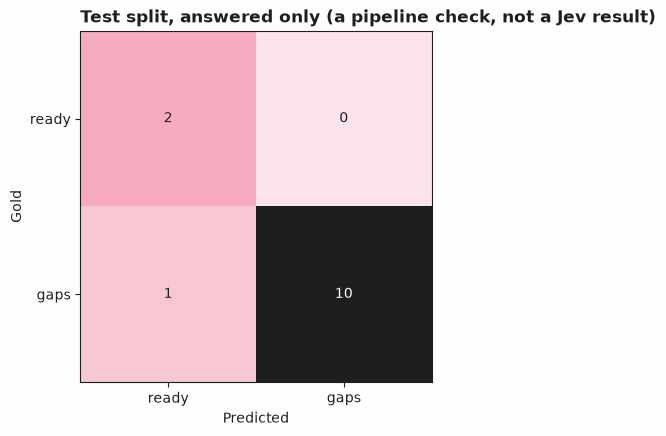

In [14]:
answered_examples = [e for e in test_examples if test_results[e.id].outcome != helpers.REVIEW]
answered_gold = [labels[e.id]["outcome"] for e in answered_examples]
answered_predicted = [test_results[e.id].outcome for e in answered_examples]
matrix = confusion_matrix(answered_gold, answered_predicted, labels=[helpers.READY, helpers.GAPS])
width = max(len(label) for label in matrix.labels)
leader_width = max(width + len("gold "), len("predicted ->"))
header = "  ".join(f"{label:>{width}s}" for label in matrix.labels)
print(f"Test confusion matrix (answered only), gold rows by predicted columns{check}:")
print(f"  {'predicted ->':<{leader_width}s}  {header}{check}")
for gold_label, row in zip(matrix.labels, matrix.matrix.tolist(), strict=True):
    counts = "  ".join(f"{count:{width}d}" for count in row)
    leader = f"gold {gold_label:<{width}s}"
    print(f"  {leader:<{leader_width}s}  {counts}{check}")
plot_confusion_matrix(matrix, title=f"Test split, answered only{check}")

The use case's own measure: among the same 13 answered records, does the predicted gap list match the record's gold combination of evidence types exactly -- the empty set for a `ready` record, or the exact set of insufficient propositions for a `gaps` record. `exact_set_match` ([docs/evaluation.md](../../docs/evaluation.md)) counts two empty sets as a match, so a `ready` record predicted `ready` counts, not only an exact non-empty gap list.

In [15]:
answered_gold_gaps = [helpers.gold_gap_set(labels[e.id]) for e in answered_examples]
answered_predicted_gaps = [test_results[e.id].gaps for e in answered_examples]
gap_list_accuracy = exact_set_match(answered_gold_gaps, answered_predicted_gaps)
print(
    f"gap list matches gold exactly: {gap_list_accuracy:.4f} "
    f"({len(answered_examples)} answered records){check}"
)

gap list matches gold exactly: 0.9231 (13 answered records) (a pipeline check, not a Jev result)


The same pooled, per-proposition view as `validation`'s own sanity check above, now on `test` with every cut-off frozen. The shared gate is this rule's only review branch -- nothing else sends a record to review, or lets one through regardless of confidence -- so the confidence-only view (`evaluate_selective` over the pooled decisions) and the rule's own outcomes view (`evaluate_outcomes` over `pool_label_outcomes`) describe the same gate from the same granularity and agree on every field but `threshold` (undefined, not merely unreported, for the outcomes view); printed side by side rather than asserted, so a reader can see the agreement rather than take it on faith.

In [16]:
test_ids = [e.id for e in test_examples]
test_pooled_correct, test_pooled_confidence, test_pooled_keys = pool_label_decisions(
    test_ids, list(helpers.LABELS), test_gold, test_noul, thresholds
)
pooled_selective = evaluate_selective(test_pooled_correct, test_pooled_confidence, gate)

test_decisions = {e.id: helpers.decide_labels(decide(e), thresholds, gate) for e in test_examples}
accepted_by_label = {
    label: [not test_decisions[e.id][label].gated for e in test_examples]
    for label in helpers.LABELS
}
tag_by_label = {
    label: [test_decisions[e.id][label].tag for e in test_examples] for label in helpers.LABELS
}
pooled_accepted, pooled_correct, _pooled_keys = pool_label_outcomes(
    test_ids, list(helpers.LABELS), test_gold, accepted_by_label, tag_by_label
)
pooled_outcomes = evaluate_outcomes(pooled_accepted, pooled_correct)

print(f"pooled, {len(test_pooled_correct)} label decisions{check}")
print(f"ungated accuracy: {sum(test_pooled_correct) / len(test_pooled_correct):.4f}{check}")
print(
    f"confidence-only view:  coverage {pooled_selective.coverage:.4f}  "
    f"accuracy {pooled_selective.accuracy:.4f}  risk {pooled_selective.risk:.4f}{check}"
)
print(
    f"rule's own outcomes:   coverage {pooled_outcomes.coverage:.4f}  "
    f"accuracy {pooled_outcomes.accuracy:.4f}  risk {pooled_outcomes.risk:.4f}{check}"
)
print(f"the two agree because the confidence gate is this rule's only review branch{check}")

pooled, 57 label decisions (a pipeline check, not a Jev result)
ungated accuracy: 0.9123 (a pipeline check, not a Jev result)
confidence-only view:  coverage 0.8947  accuracy 0.9804  risk 0.0196 (a pipeline check, not a Jev result)
rule's own outcomes:   coverage 0.8947  accuracy 0.9804  risk 0.0196 (a pipeline check, not a Jev result)
the two agree because the confidence gate is this rule's only review branch (a pipeline check, not a Jev result)


In [17]:
print("Test records the composed outcome got wrong, and what the gate saw on each proposition:")
for example in test_examples:
    result = test_results[example.id]
    gold_outcome = labels[example.id]["outcome"]
    if result.outcome != helpers.REVIEW and result.outcome != gold_outcome:
        decisions = test_decisions[example.id]
        detail = ", ".join(
            f"{label} {decisions[label].noul:.2f} (confidence {decisions[label].confidence:.4f})"
            for label in helpers.LABELS
        )
        print(
            f"  {example.id}: gold {gold_outcome} {sorted(helpers.gold_gap_set(labels[example.id]))}, composed {result.outcome} -- {detail}"
        )

Test records the composed outcome got wrong, and what the gate saw on each proposition:
  t19: gold gaps ['rollback_evidence'], composed ready -- implementation_evidence 0.95 (confidence 0.9000), validation_evidence 0.96 (confidence 0.9200), rollback_evidence 0.90 (confidence 0.8000)


`t19` clears the frozen gate on all three propositions, printed in the cell above, and is still wrong: it sits at `rollback_evidence` 0.90, just above the 0.84 threshold, with confidence exactly 0.80 -- the frozen gate itself, so it counts as answered -- while its gold label is `False`: like `d02` shown earlier, this record names where its rollback plan is documented without describing what it actually does, and the stored reading clears the business threshold anyway. This is exactly the blind spot named above: `noul_confidence` measures distance from 0.5, never distance from the frozen threshold, so a proposition whose business threshold sits near one end of the scale can read as confidently right up to, and just past, the line that decides its tag. A shared gate over three propositions cannot be told where any one proposition's own threshold sits without ceasing to be one shared number, so this is a property of pooling the gate at all, not a bug to tune away with a different gate value.

The real queue is built once here, from every `validation` and `test` record `review_checklist` sends to review -- `demo` records are excluded, since neither is ever reviewed and they were never scored in the first place. `ReviewQueue` has no reordering of its own, so the full list is sorted once by `helpers.review_sort_key` before any of it is submitted, which is what makes the result globally ordered rather than the four-record preview's own approximation above.

In [18]:
to_review = [
    (e.id, e, test_results[e.id] if e.split == "test" else val_results[e.id])
    for e in val_examples + test_examples
]
to_review = [row for row in to_review if row[2].outcome == helpers.REVIEW]
to_review.sort(key=lambda row: (helpers.review_sort_key(row[2]), row[0]))

queue = ReviewQueue()
for example_id, example, result in to_review:
    item = helpers.queue_item(example_id, example.fields, result)
    gating = helpers.gating_label(result)
    queue.submit(item, result.reason, answer=decide(example)[gating])

print(f"queue holds {len(queue)} records, least confident first{check}")
for row in queue.to_dicts():
    print(f"  {row['item']['id']}: {row['reason']}")

queue holds 12 records, least confident first (a pipeline check, not a Jev result)
  t08: confidence below the threshold
  t14: confidence below the threshold
  t12: confidence below the threshold
  v08: confidence below the threshold
  t18: confidence below the threshold
  v14: confidence below the threshold
  t17: confidence below the threshold
  v12: confidence below the threshold
  v18: confidence below the threshold
  v17: confidence below the threshold
  t13: confidence below the threshold
  v19: confidence below the threshold


## What was and was not measured

Not measured live: the offline run replays synthetic answers written for this recipe, so its numbers check the pipeline and say nothing about how Jev performs. A deterministic checklist built on top of these three propositions is only as good as they are: the one confidently-wrong record shown above, `t19`, names where its rollback plan is documented without describing what it actually does -- the same shape of mistake this recipe's own fixtures were written to exercise, not a general claim about how often real change records would fool it. Nothing here approves, blocks, merges, or deploys anything; every outcome is a label this recipe attaches to a change record, and acting on it is left to whatever system calls this rule.

In [19]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test records")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test records")

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 19 validation and 19 test records


## Next steps

- Add a harder near-miss to `ROWS` in `build_fixtures.py` -- a record that mentions implementation or validation work without describing it, phrased even more plausibly -- and see which threshold or the gate it lands on.
- Loosen the confidence gate (a lower `target_accuracy`, or `min_coverage` in its place) and watch `evaluate_selective`'s coverage rise on `test` while its risk rises too; `t19`, the record named above, never moves under a looser gate, because loosening only accepts more, never fewer, and its confidence already sits exactly at the current gate (0.80) -- only a *tighter* gate, one step higher, would newly send it to review.
- Neighbouring recipes: [`02-refund-intent-detection`](../02-refund-intent-detection/) (a single `Noul` proposition, in this recipe's own `Workflow & service operations` category) and [`18-duplicate-incident-matching`](../18-duplicate-incident-matching/) (a `Choice` question, also `Workflow & service operations`); and [`34-evidence-relationship-labels`](../34-evidence-relationship-labels/), which keeps this recipe's habit of judging whether evidence is sufficient, but narrows the question from "is there enough evidence for this change" to "what specific relationship does this one passage of evidence support."